# Log-sekuens — Klasifikasi Sesi (bag-of-events)
**Kapan dipakai:** data berupa event log (satu baris = satu kejadian dengan id sesi, aktivitas,
waktu) dan tiap sesi punya label (bot vs manusia, beli vs tidak, telat vs tepat waktu,
penipuan vs normal).

**Idenya:** hitung berapa kali tiap aktivitas muncul di sesi (bag-of-events), tambah jumlah
event dan durasi sesi → satu baris per sesi → klasifikasi.

**Langkah:**
1. Buat label sesi, ambil hanya event awal.
2. Tabel sesi × aktivitas (`crosstab`) + jumlah event + durasi.
3. Split, model, submission.

**Data demo:** log denda lalu lintas Italia (10.002 kasus, 11 aktivitas). Label = kasus akhirnya
"Send for Credit Collection" (denda tidak dibayar). Supaya tidak curang, feature hanya memakai
`MAX_EVENTS` kejadian pertama (prediksi dini) dan aktivitas label dibuang dari feature.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/log"   # GANTI saat lomba
LOG_CSV = f"{DATA_FOLDER}/denda_lalu_lintas.csv"

CASE_COL = "case_id"             # kolom id sesi
ACTIVITY_COL = "aktivitas"       # kolom nama kejadian
TIME_COL = "waktu"               # kolom waktu kejadian
LABEL_ACTIVITY = "Send for Credit Collection"   # demo: sesi berlabel 1 bila memuat aktivitas ini
MAX_EVENTS = 4                   # pakai hanya N kejadian pertama tiap sesi
TEST_SIZE = 0.3
SEED = 42

## Baca data

In [3]:
log = pd.read_csv(LOG_CSV, parse_dates=[TIME_COL])
log = log.sort_values([CASE_COL, TIME_COL])
print(log.shape, "|", log[CASE_COL].nunique(), "sesi")
log.head(8)

(37255, 4) | 10002 sesi


,case_id,aktivitas,waktu,resource
0,A1,Create Fine,2006-07-23 22:00:00+00:00,NaN
1,A1,Send Fine,2006-12-04 23:00:00+00:00,NaN
2,A1006,Create Fine,2006-08-07 22:00:00+00:00,NaN
3,A1006,Payment,2006-09-11 22:00:00+00:00,NaN
4,A10061,Create Fine,2007-03-07 23:00:00+00:00,NaN
5,A10061,Send Fine,2007-07-16 22:00:00+00:00,NaN
6,A10061,Insert Fine Notification,2007-08-01 22:00:00+00:00,NaN
7,A10061,Add penalty,2007-09-30 22:00:00+00:00,NaN


## Langkah 1 — label sesi dan potong event awal
Label dibuat dari log lengkap. Feature dari `MAX_EVENTS` kejadian pertama, tanpa aktivitas label.
Saat lomba: label sesi biasanya diberi panitia, baca dengan `pd.read_csv`.

In [4]:
is_label_event = log[ACTIVITY_COL] == LABEL_ACTIVITY
positive_cases = log.loc[is_label_event, CASE_COL].unique()
labels = pd.Series(0, index=log[CASE_COL].unique())
labels[positive_cases] = 1

event_number = log.groupby(CASE_COL).cumcount()
early = log[(event_number < MAX_EVENTS) & (~is_label_event)]
print("proporsi sesi berlabel 1:", round(labels.mean(), 3))
print("event dipakai:", len(early), "dari", len(log))

proporsi sesi berlabel 1: 0.393
event dipakai: 30867 dari 37255


## Langkah 2 — feature sesi
Bag-of-events: tabel sesi × aktivitas berisi jumlah kemunculan. Ditambah jumlah event dan
durasi (hari) antara kejadian pertama dan terakhir yang dipakai.

In [5]:
features = pd.crosstab(early[CASE_COL], early[ACTIVITY_COL])
per_case = early.groupby(CASE_COL)
features["n_events"] = per_case.size()
duration = per_case[TIME_COL].max() - per_case[TIME_COL].min()
features["duration_days"] = duration.dt.total_seconds() / 86400
features = features.reindex(labels.index)
features = features.fillna(0)
print(features.shape)
features.head()

(10002, 10)


aktivitas,Add penalty,Appeal to Judge,Create Fine,Insert Date Appeal to Prefecture,Insert Fine Notification,Payment,Send Appeal to Prefecture,Send Fine,n_events,duration_days
A1,0,0,1,0,0,0,0,1,2,134.041667
A1006,0,0,1,0,0,1,0,0,2,35.000000
A10061,1,0,1,0,1,0,0,1,4,206.958333
A10068,1,0,1,0,1,0,0,1,4,205.958333
A10138,1,0,1,0,1,0,0,1,4,195.958333


## Langkah 3a — split dan model
Pilih SATU model: hapus `#` di depan baris yang ingin dipakai, beri `#` pada baris lain.

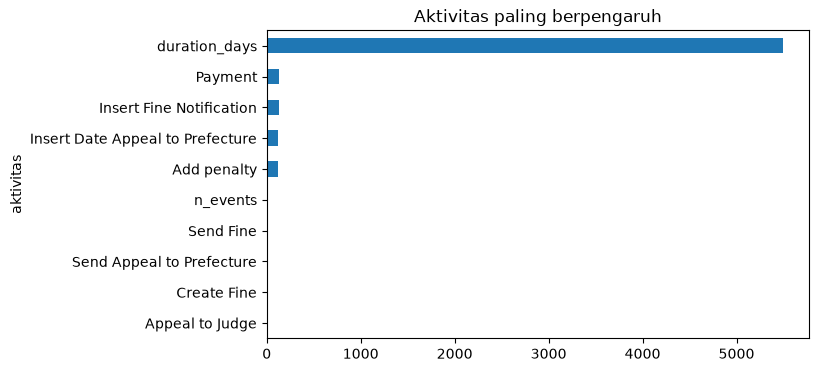

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    features, labels, test_size=TEST_SIZE, random_state=SEED, stratify=labels)

model = LGBMClassifier(n_estimators=200, learning_rate=0.05, random_state=SEED, verbose=-1)
# model = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, n_jobs=4, random_state=SEED)
model.fit(X_train, y_train)

importance = pd.Series(model.feature_importances_, index=features.columns)
importance = importance.sort_values()
importance.plot.barh(figsize=(7, 4))
plt.title("Aktivitas paling berpengaruh")
plt.show()

## Langkah 3b — submission
Saat lomba: buat feature sesi test dengan cara yang sama, latih model di semua sesi berlabel.

In [7]:
predictions = model.predict(X_test)

submission = pd.DataFrame()
submission["case_id"] = X_test.index
submission["label"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,case_id,label
0,N93469,0
1,S86372,1
2,S147133,1
3,P4464,0
4,N28301,1


## Cek dengan kunci jawaban (HAPUS saat lomba)

In [8]:
probabilities = model.predict_proba(X_test)
print("F1     :", round(f1_score(y_test, predictions), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, probabilities[:, 1]), 4))
print(classification_report(y_test, predictions))

F1     : 0.8825
ROC-AUC: 0.9244
              precision    recall  f1-score   support

           0       0.99      0.84      0.91      1822
           1       0.80      0.98      0.88      1179

    accuracy                           0.90      3001
   macro avg       0.89      0.91      0.90      3001
weighted avg       0.91      0.90      0.90      3001

